# Disaster Type Classifier: Model Check

Run this **after** `train_disaster_types.py` has finished.
Put this notebook in the **same folder** as `train_disaster_types.py` and the `best_model.pt` .

Sections: 1. Load model, 2. Predict on test set, 3. Metrics, 4. Confusion matrix, 5. Confidence / "needs review" analysis, 6. Look at examples, 7. Try your own image, 8. Grad-CAM (what the model looked at)

## 1. Load model

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import train_disaster_types as T  # must be in the same folder as this notebook
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CKPT = Path("best_model.pt")

state = torch.load(CKPT, map_location=device)
classes = state["classes"]
T.IMG_SIZE = state["img_size"]  # make sure preprocessing matches training

model = T.DisasterClassifier(state["model_name"], len(classes)).to(device)
model.load_state_dict(state["model"])
model.eval()

class_to_idx = {c: i for i, c in enumerate(classes)}
_, eval_tf = T.build_transforms()
print("Device:", device)
print("Model:", state["model_name"], "| image size:", state["img_size"])
print("Classes:", classes)

Device: cpu
Model: convnext_tiny | image size: 224
Classes: ['earthquake', 'fire', 'flood', 'hurricane', 'landslide', 'not_disaster', 'other_disaster']


## 2. Predict on the test set

In [2]:
test_df = T.load_split(T.TEST_TSV, "test")
test_ds = T.DisasterDataset(test_df, class_to_idx, eval_tf)
loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=0)

probs_list = []
with torch.no_grad():
    for x, _ in tqdm(loader):
        probs_list.append(torch.softmax(model(x.to(device)), dim=1).cpu())

probs = torch.cat(probs_list).numpy()
y_true = np.array(test_ds.labels)
y_pred = probs.argmax(1)
conf = probs.max(1)
paths = test_df["full_path"].tolist()
print("Done:", len(y_true), "test images")

[test] 3195 images


  0%|          | 0/50 [00:00<?, ?it/s]

Done: 3195 test images


## 3. Metrics

Accuracy : 0.8391
Macro-F1 : 0.8153

                precision    recall  f1-score   support

    earthquake      0.836     0.871     0.853       404
          fire      0.899     0.925     0.912       280
         flood      0.869     0.878     0.874       599
     hurricane      0.740     0.696     0.717       352
     landslide      0.853     0.869     0.861       268
  not_disaster      0.888     0.907     0.898       990
other_disaster      0.632     0.556     0.592       302

      accuracy                          0.839      3195
     macro avg      0.817     0.815     0.815      3195
  weighted avg      0.836     0.839     0.837      3195



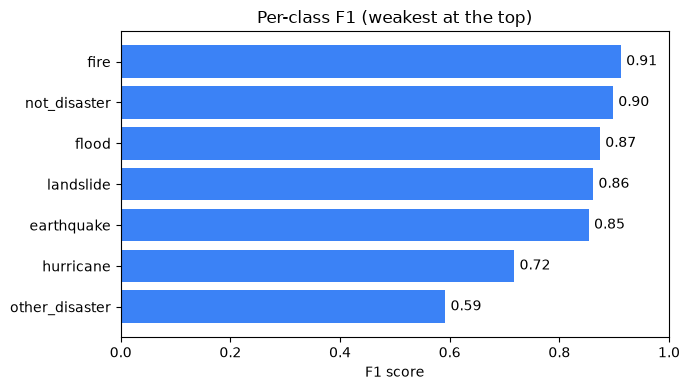

In [3]:
print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro-F1 : {f1_score(y_true, y_pred, average='macro'):.4f}\n")
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

# per-class F1 bar chart
f1s = f1_score(y_true, y_pred, average=None)
order = np.argsort(f1s)
plt.figure(figsize=(7, 4))
plt.barh([classes[i] for i in order], f1s[order], color="#3b82f6")
plt.xlim(0, 1)
plt.xlabel("F1 score")
plt.title("Per-class F1 (weakest at the top)")
for y, v in enumerate(f1s[order]):
    plt.text(v + 0.01, y, f"{v:.2f}", va="center")
plt.tight_layout()
plt.show()

## 4. Confusion matrix
Rows = true class, columns = predicted class. The left plot shows counts; the right plot shows the share of each true class (recall).

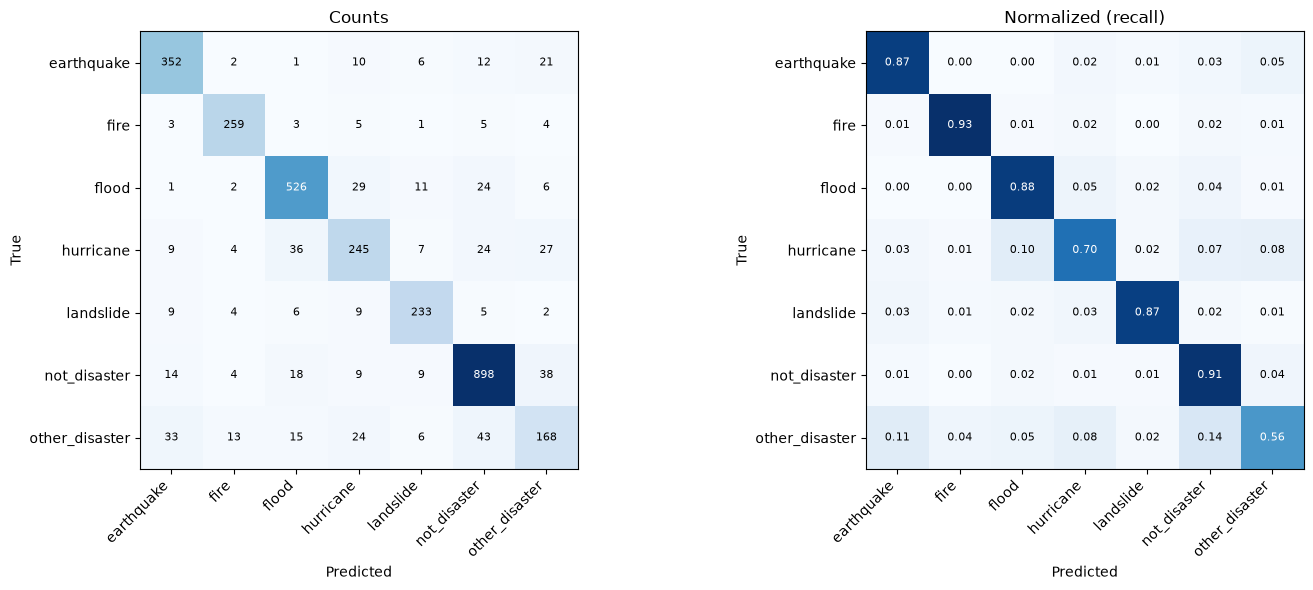

Top confusions (true -> predicted):
  other_disaster  -> not_disaster    43
  not_disaster    -> other_disaster  38
  hurricane       -> flood           36
  other_disaster  -> earthquake      33
  flood           -> hurricane       29
  hurricane       -> other_disaster  27
  flood           -> not_disaster    24
  hurricane       -> not_disaster    24


In [4]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, data, title, fmt in [
    (axes[0], cm, "Counts", "d"),
    (axes[1], cm_norm, "Normalized (recall)", ".2f"),
]:
    im = ax.imshow(data, cmap="Blues")
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    thr = data.max() / 2
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(
                j,
                i,
                format(data[i, j], fmt),
                ha="center",
                va="center",
                color="white" if data[i, j] > thr else "black",
                fontsize=8,
            )
plt.tight_layout()
plt.show()

# most common mistakes
pairs = [
    (classes[i], classes[j], cm[i, j])
    for i in range(len(classes))
    for j in range(len(classes))
    if i != j and cm[i, j] > 0
]
print("Top confusions (true -> predicted):")
for t, p, n in sorted(pairs, key=lambda x: -x[2])[:8]:
    print(f"  {t:15s} -> {p:15s} {n}")

## 5. Confidence and the "needs review" threshold
If confidence is below the threshold, the hub sends the image to a human. This table shows the trade-off: a higher threshold means more reviews but fewer wrong auto-decisions.

,threshold,auto-handled %,sent to review %,accuracy on auto-handled
0,0.0,100.0,0.0,0.8391
1,0.4,97.9,2.1,0.8511
2,0.5,94.3,5.7,0.8663
3,0.6,89.5,10.5,0.8831
4,0.7,83.8,16.2,0.8999
5,0.8,55.1,44.9,0.9069
6,0.9,22.1,77.9,0.9279


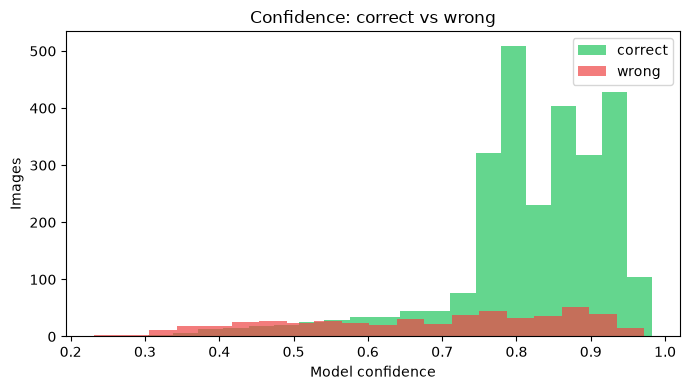

In [5]:
rows = []
for th in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf >= th
    rows.append(
        {
            "threshold": th,
            "auto-handled %": round(100 * keep.mean(), 1),
            "sent to review %": round(100 * (1 - keep.mean()), 1),
            "accuracy on auto-handled": round(
                float((y_pred[keep] == y_true[keep]).mean()), 4
            )
            if keep.any()
            else None,
        }
    )
display(pd.DataFrame(rows))

plt.figure(figsize=(7, 4))
plt.hist(conf[y_pred == y_true], bins=20, alpha=0.7, label="correct", color="#22c55e")
plt.hist(conf[y_pred != y_true], bins=20, alpha=0.7, label="wrong", color="#ef4444")
plt.xlabel("Model confidence")
plt.ylabel("Images")
plt.legend()
plt.title("Confidence: correct vs wrong")
plt.tight_layout()
plt.show()

## 6. Look at examples

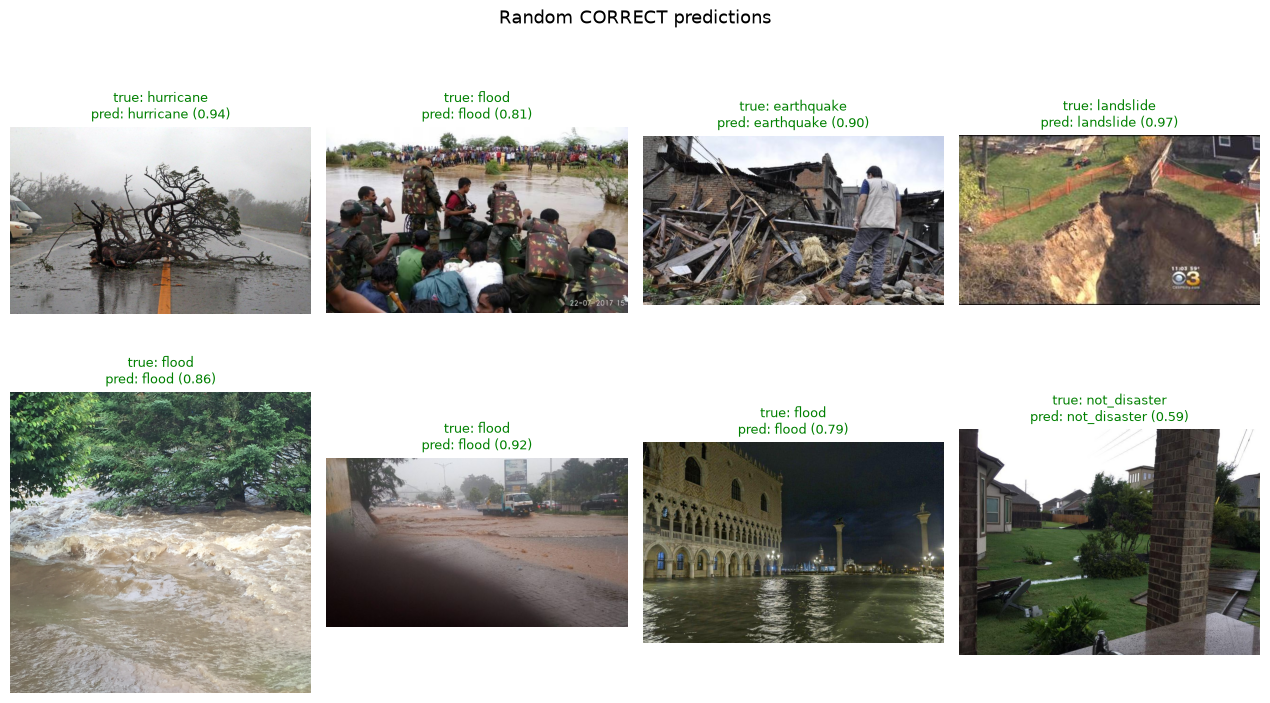

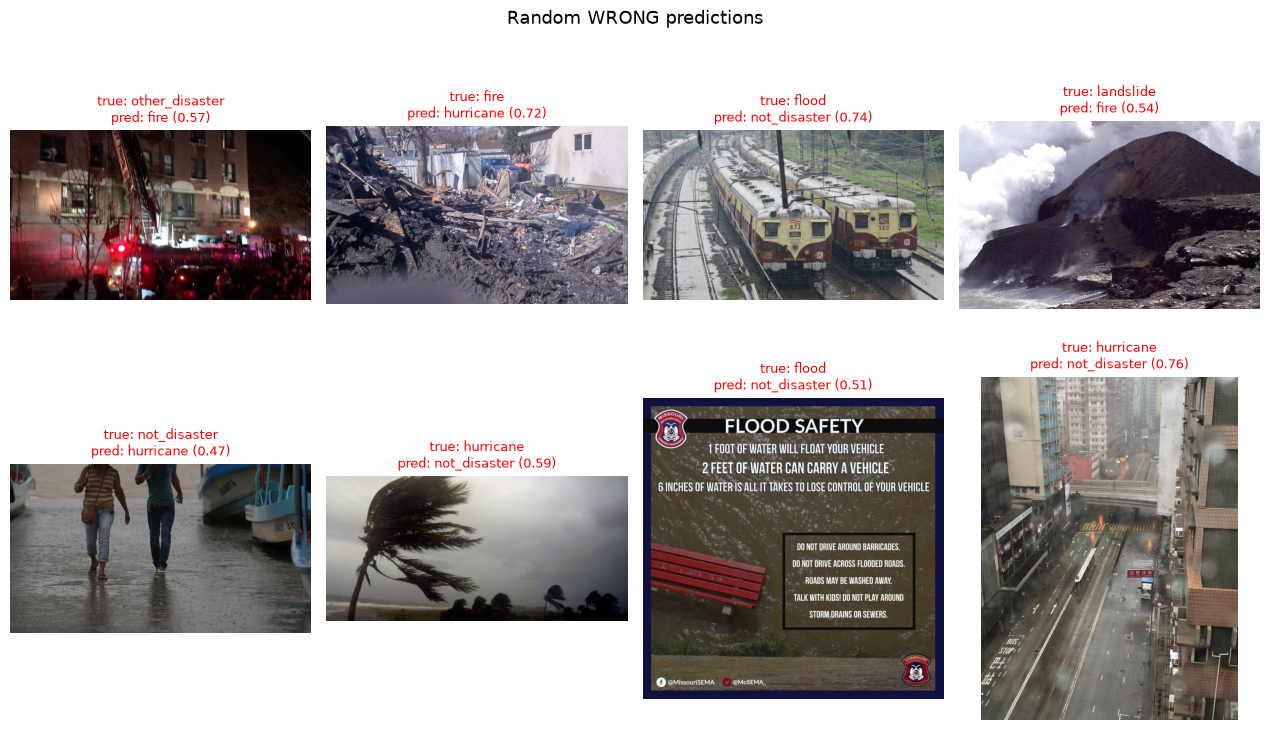

In [6]:
def show_samples(indices, title, cols=4, size=3.2):
    indices = list(indices)
    if not indices:
        print("Nothing to show.")
        return
    rows = (len(indices) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size + 0.5)))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indices, strict=False):
        ax.imshow(Image.open(paths[i]).convert("RGB"))
        ok = y_pred[i] == y_true[i]
        ax.set_title(
            f"true: {classes[y_true[i]]}\npred: {classes[y_pred[i]]} ({conf[i]:.2f})",
            fontsize=9,
            color="green" if ok else "red",
        )
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


random.seed(0)
wrong = np.where(y_pred != y_true)[0]
right = np.where(y_pred == y_true)[0]

show_samples(
    random.sample(list(right), min(8, len(right))), "Random CORRECT predictions"
)
show_samples(random.sample(list(wrong), min(8, len(wrong))), "Random WRONG predictions")

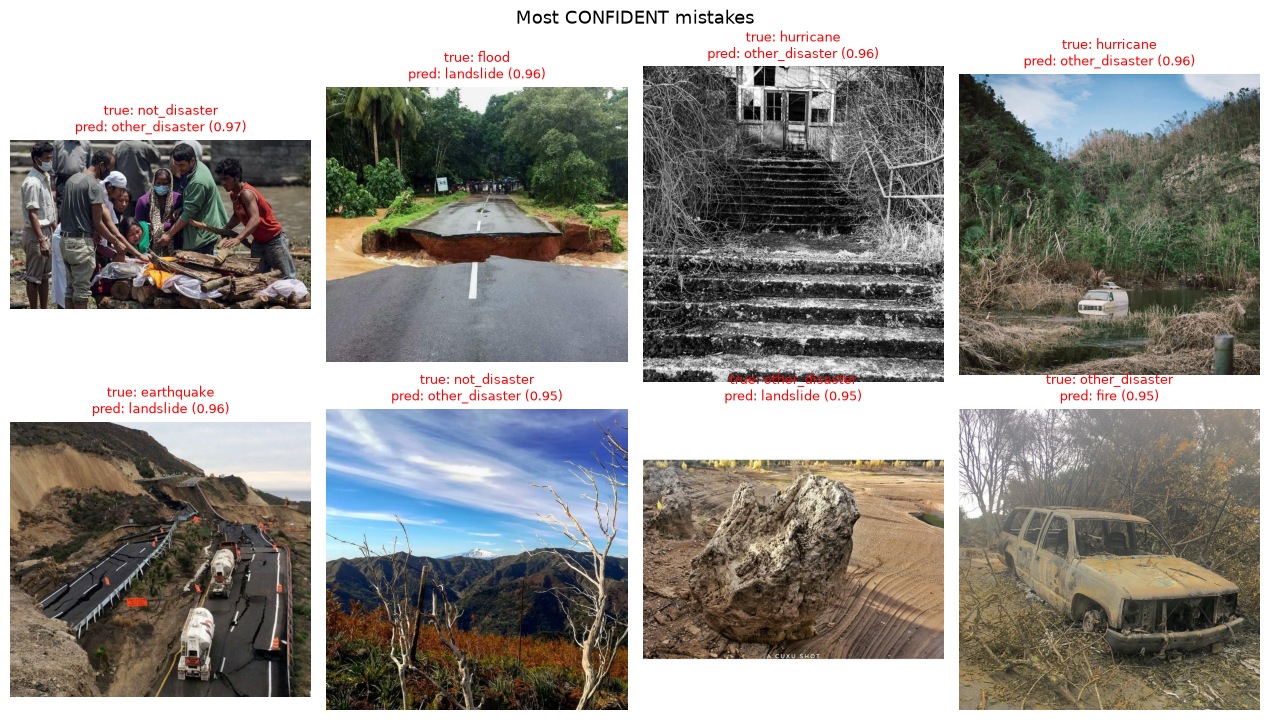

In [7]:
# Most confident mistakes (often label noise or truly ambiguous images)
worst = wrong[np.argsort(-conf[wrong])][:8]
show_samples(worst, "Most CONFIDENT mistakes")

landslide: 35 missed out of 268


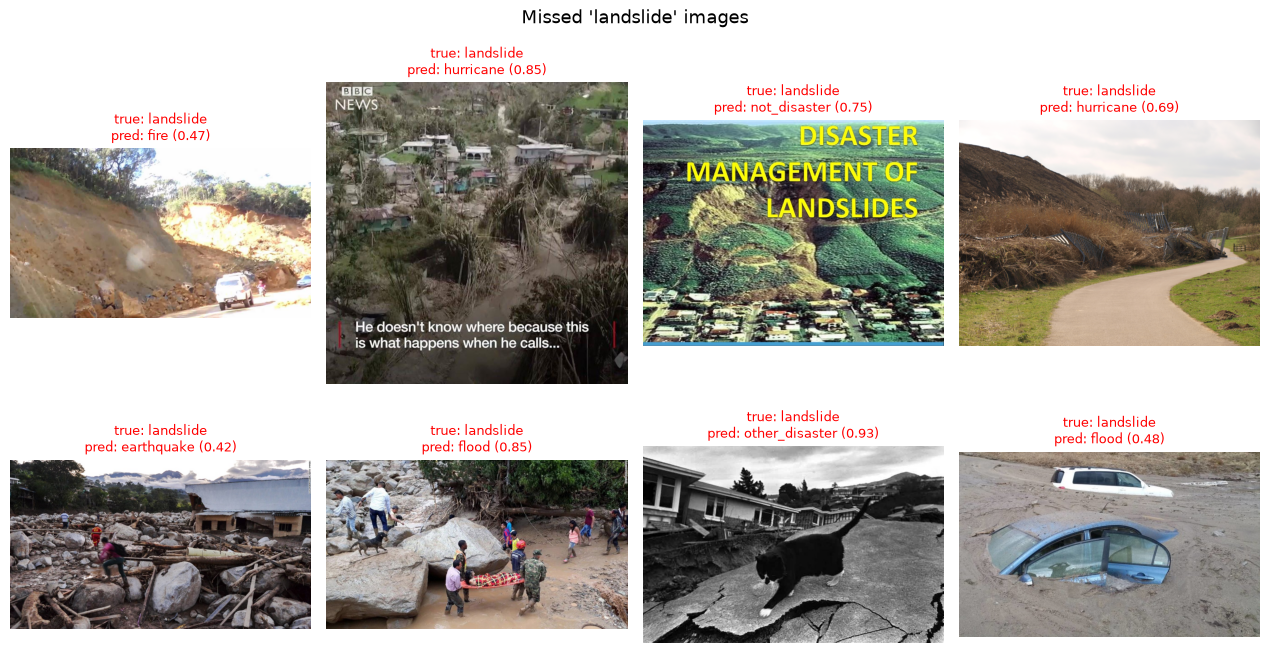

In [8]:
# Look at one class in detail. Change the class name.
CLASS_TO_INSPECT = "landslide"
idx = class_to_idx[CLASS_TO_INSPECT]
mis = np.where((y_true == idx) & (y_pred != idx))[0]
print(f"{CLASS_TO_INSPECT}: {len(mis)} missed out of {(y_true == idx).sum()}")
show_samples(mis[:8], f"Missed '{CLASS_TO_INSPECT}' images")

## 7. Try your own image
Set `IMAGE_PATH` to any image on your computer (for example a photo you collected from social media).

In [ ]:
def predict_pil(img, review_threshold=0.6):
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        p = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    top = p.argsort()[::-1][:3]
    return {
        "prediction": classes[top[0]],
        "confidence": float(p[top[0]]),
        "top3": [(classes[i], float(p[i])) for i in top],
        "needs_review": bool(p[top[0]] < review_threshold),
        "all_probs": p,
    }


def predict_file(path, review_threshold=0.6):
    img = Image.open(path)
    r = predict_pil(img, review_threshold)
    _, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
    a.imshow(img.convert("RGB"))
    a.axis("off")
    a.set_title(
        f"{r['prediction']} ({r['confidence']:.2f})"
        + ("  [NEEDS REVIEW]" if r["needs_review"] else "")
    )
    b.barh(classes, r["all_probs"], color="#3b82f6")
    b.set_xlim(0, 1)
    b.set_xlabel("probability")
    plt.tight_layout()
    plt.show()
    return r


IMAGE_PATH = r"C:\path\to\your\image.jpg"  # <-- change this
# result = predict_file(IMAGE_PATH)
# print(result["top3"])

## Quick checklist for reading your results

- **Macro-F1 / per-class F1:** which class is weakest? (landslide and "other disaster" are often hardest.)
- **Confusion matrix:** are mistakes between similar classes (flood vs hurricane) or with `not_disaster`?
- **Confident mistakes:** are they model errors or wrong labels? Label noise is common in crowd-labeled tweets.
- **Threshold table:** pick the "needs review" threshold that balances human workload against error rate.